# Raw DINO patch features vs Aligned VegAnn patch features

Does the VegAnn Agriclip aligner preserve local patch semantics? 
using Cosine similarity, PCA, t0SNE , vegetation vs soil distributions, statsistics

In [15]:
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from datasets import load_dataset

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from PIL import Image

plt.rcParams["figure.figsize"] = (6,6)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [16]:
PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

VEGANN_ALIGNER = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

sys.path.append(
    str(ALIGNMENT_DIR)
)

print(PROJECT_ROOT)
print(AGRICLIP_ROOT)
print(VEGANN_ALIGNER)

/home/zahranadeem/thesis
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
/home/zahranadeem/thesis/vegann_aligner.pth


In [17]:
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(len(train_hf))
print(len(val_hf))

3020
755


In [18]:
def get_image(idx, split):

    image = split[idx]["image"]

    if isinstance(image, Image.Image):
        image = np.array(image)

    return image


def get_mask(idx, split):
    mask_obj = split[idx]["mask"]
    
    # Force transformation to a clean, decoupled NumPy array
    if hasattr(mask_obj, "convert"):
        mask_obj = mask_obj.convert("L")  # Standardize PIL images to grayscale mode
    
    mask_np = np.array(mask_obj, dtype=np.uint8)
    
    # Standardize layout to 2D matrix shape [Height, Width]
    if mask_np.ndim == 3:
        if mask_np.shape[0] == 1 or mask_np.shape[0] == 3:
            mask_np = mask_np[0, :, :]  # Slice away channel artifacts
        elif mask_np.shape[-1] == 1 or mask_np.shape[-1] == 3:
            mask_np = mask_np[:, :, 0]
            
    return np.squeeze(mask_np)

In [19]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model.eval()
dino_model.to(device)

print(type(dino_model))

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


<class 'torchvision.models.resnet.ResNet'>


In [20]:
feature_map = None

def hook_fn(module, input, output):
    global feature_map
    feature_map = output

hook_handle = dino_model.layer4.register_forward_hook(
    hook_fn
)

print("Forward hook registered.")

Forward hook registered.


In [21]:
#Extract 7 x7 Dino feature map
@torch.no_grad()
def extract_patch_features(image):

    global feature_map

    image = cv2.resize(
        image,
        (224,224)
    )

    image = image.astype(np.float32) / 255.

    image = torch.from_numpy(image)

    image = image.permute(
        2,
        0,
        1
    )

    image = image.unsqueeze(0)

    image = image.to(device)

    dino_model(image)

    fmap = feature_map.squeeze(0)

    fmap = fmap.permute(
        1,
        2,
        0
    )

    patches = fmap.reshape(
        -1,
        2048
    )

    return patches.cpu()

In [22]:
#est patch exraction 
sample_image = get_image(
    12,
    val_hf
)

patches = extract_patch_features(
    sample_image
)

print("Patch tensor shape:")
print(patches.shape)

Patch tensor shape:
torch.Size([49, 2048])


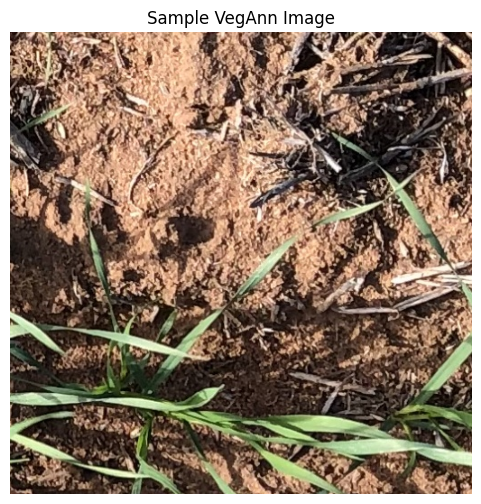

In [23]:
#Visualize 
plt.figure(figsize=(6,6))

plt.imshow(sample_image)

plt.title("Sample VegAnn Image")

plt.axis("off")

plt.show()

In [24]:
def get_mask(idx, split):

    mask = split[idx]["mask"]

    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    return mask

In [25]:
sample = val_hf[12]


print(sample.keys())

for key in sample.keys():
    value = sample[key]

    print("\n------------------")
    print(key)
    print(type(value))

    if isinstance(value, Image.Image):
        print("Image size:", value.size)

dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])

------------------
image
<class 'PIL.PngImagePlugin.PngImageFile'>
Image size: (512, 512)

------------------
mask
<class 'PIL.PngImagePlugin.PngImageFile'>
Image size: (512, 512)

------------------
System
<class 'str'>

------------------
Orientation
<class 'str'>

------------------
latitude
<class 'float'>

------------------
longitude
<class 'float'>

------------------
date
<class 'str'>

------------------
LocAcc
<class 'int'>

------------------
Species
<class 'str'>

------------------
Owner
<class 'str'>

------------------
Dataset-Name
<class 'str'>

------------------
TVT-split1
<class 'str'>

------------------
TVT-split2
<class 'str'>

------------------
TVT-split3
<class 'str'>

------------------
TVT-split4
<class 'str'>

------------------
TVT-split5
<class 'str'>


(512, 512)
uint8
[  0 255]


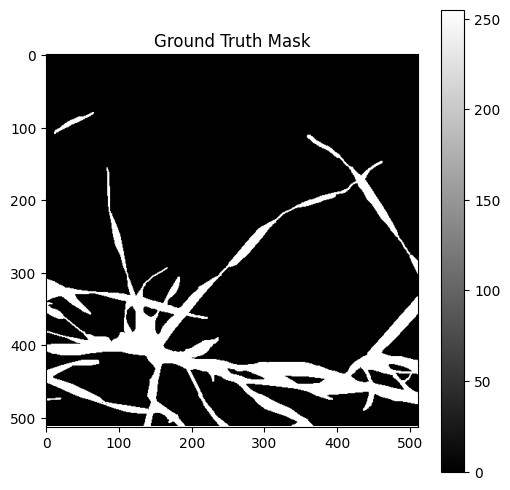

In [26]:
mask = get_mask(12, val_hf)

print(mask.shape)
print(mask.dtype)
print(np.unique(mask))

plt.figure(figsize=(6,6))
plt.imshow(mask, cmap="gray")
plt.colorbar()
plt.title("Ground Truth Mask")
plt.show()

In [27]:
print("Mask shape:", mask.shape)

print("Unique values:", np.unique(mask))

print("Vegetation pixels:", np.sum(mask == 255))

print("Background pixels:", np.sum(mask == 0))

print("Vegetation ratio:", np.mean(mask == 255))

Mask shape: (512, 512)
Unique values: [  0 255]
Vegetation pixels: 32112
Background pixels: 230032
Vegetation ratio: 0.12249755859375


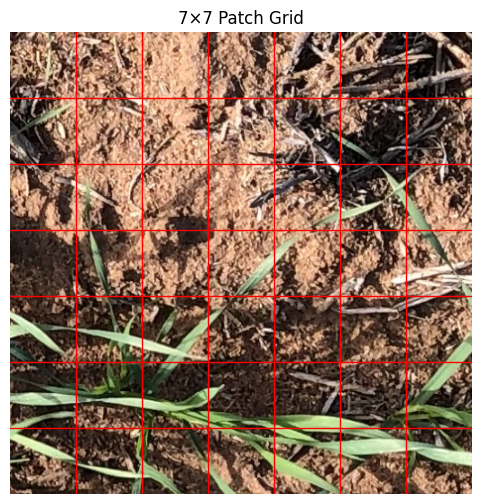

In [28]:
#Display the grid 7x7 
fig, ax = plt.subplots(
    figsize=(6,6)
)

ax.imshow(sample_image)

H, W = sample_image.shape[:2]

for i in range(1,7):

    ax.axhline(
        i*H/7,
        color="red",
        linewidth=1
    )

    ax.axvline(
        i*W/7,
        color="red",
        linewidth=1
    )

ax.set_title(
    "7×7 Patch Grid"
)

ax.axis("off")

plt.show()

In [29]:
#Verify row correspondance 
patch_ids = np.arange(
    49
).reshape(
    7,
    7
)

print(patch_ids)

[[ 0  1  2  3  4  5  6]
 [ 7  8  9 10 11 12 13]
 [14 15 16 17 18 19 20]
 [21 22 23 24 25 26 27]
 [28 29 30 31 32 33 34]
 [35 36 37 38 39 40 41]
 [42 43 44 45 46 47 48]]


In [30]:
#Load TexttoConcept and aligner
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(VEGANN_ALIGNER)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")

VegAnn aligner loaded.


In [31]:
#align all 49 patches 
def align_patch_features(
    patch_features
):

    patch_features = torch.tensor(
        patch_features,
        dtype=torch.float32,
        device=device
    )

    aligned = aligner.get_aligned_representation(
        patch_features
    )

    return aligned.cpu()

In [32]:
#Test the aligner 
aligned = align_patch_features(
    patches
)

print("Raw patches :", patches.shape)
print("Aligned patches :", aligned.shape)

Raw patches : torch.Size([49, 2048])
Aligned patches : torch.Size([49, 512])


/tmp/ipykernel_1029072/2163179919.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  patch_features = torch.tensor(


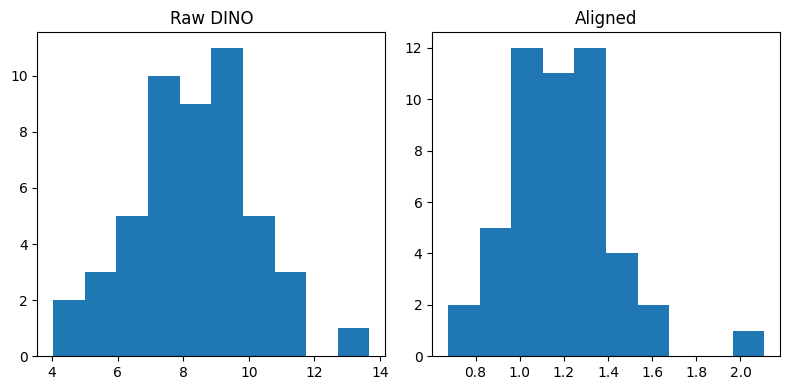

In [33]:
#Compare feature distributions 
# compare the norm of every patch before and after alignment.
raw_norm = torch.norm(
    patches,
    dim=1
).numpy()

aligned_norm = torch.norm(
    aligned,
    dim=1
).numpy()

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)

plt.hist(
    raw_norm,
    bins=10
)

plt.title("Raw DINO")

plt.subplot(1,2,2)

plt.hist(
    aligned_norm,
    bins=10
)

plt.title("Aligned")

plt.tight_layout()

plt.show()

In [35]:
#Prompts 
POSITIVE_PROMPTS = [

    "A crop field populated by healthy plants, captured from a nadir view using a handheld camera.",

    "An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.",

    "A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.",

    "An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.",

    "Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.",

    "Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera."

]
NEGATIVE_PROMPTS = [

    "Bare agricultural soil, captured from a nadir view using a handheld camera.",

    "An empty agricultural field without vegetation, captured from a nadir view using a handheld camera.",

    "Dry exposed soil, captured from a nadir view using a handheld camera.",

    "Agricultural land without crops, captured from a nadir view using a handheld camera.",

    "Only background soil visible, captured from a nadir view using a handheld camera.",

    "A field without vegetation, captured from a nadir view using a handheld camera."

]


In [36]:
#Compute text embeddings 
positive_embeddings = []

for prompt in POSITIVE_PROMPTS:

    emb = text_to_concept.encode_text(
        [[prompt]]
    )

    positive_embeddings.append(
        emb.squeeze().cpu().numpy()
    )

positive_embeddings = np.stack(
    positive_embeddings
)

negative_embeddings = []

for prompt in NEGATIVE_PROMPTS:

    emb = text_to_concept.encode_text(
        [[prompt]]
    )

    negative_embeddings.append(
        emb.squeeze().cpu().numpy()
    )

negative_embeddings = np.stack(
    negative_embeddings
)

print(positive_embeddings.shape)
print(negative_embeddings.shape)

(6, 512)
(6, 512)


In [37]:
# Compare raw DINO patches with aligned patches
# Compute cosine similarity between every patch and veg prompts
#wheter the aligner improves or degrades local semantic info? 


def normalize_numpy(x):

    x = x / np.linalg.norm(
        x,
        axis=1,
        keepdims=True
    )

    return x


raw_features = normalize_numpy(
    patches.numpy()
)

aligned_features = normalize_numpy(
    aligned.numpy()
)

positive_embeddings = normalize_numpy(
    positive_embeddings
)

negative_embeddings = normalize_numpy(
    negative_embeddings
)

print(raw_features.shape)
print(aligned_features.shape)



(49, 2048)
(49, 512)


In [38]:
#cosine similarity
positive_similarity = aligned_features @ positive_embeddings.T

negative_similarity = aligned_features @ negative_embeddings.T

print(positive_similarity.shape)
print(negative_similarity.shape)

(49, 6)
(49, 6)


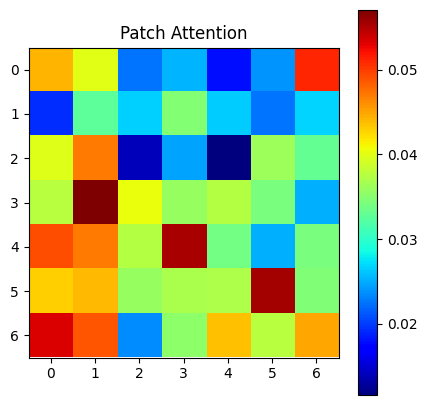

In [39]:
#best vegetation score for each patch 
best_positive = positive_similarity.max(
    axis=1
)

best_negative = negative_similarity.max(
    axis=1
)

attention = best_positive - best_negative

attention = attention.reshape(
    7,
    7
)

plt.figure(figsize=(5,5))

plt.imshow(
    attention,
    cmap="jet"
)

plt.colorbar()

plt.title(
    "Patch Attention"
)

plt.show()

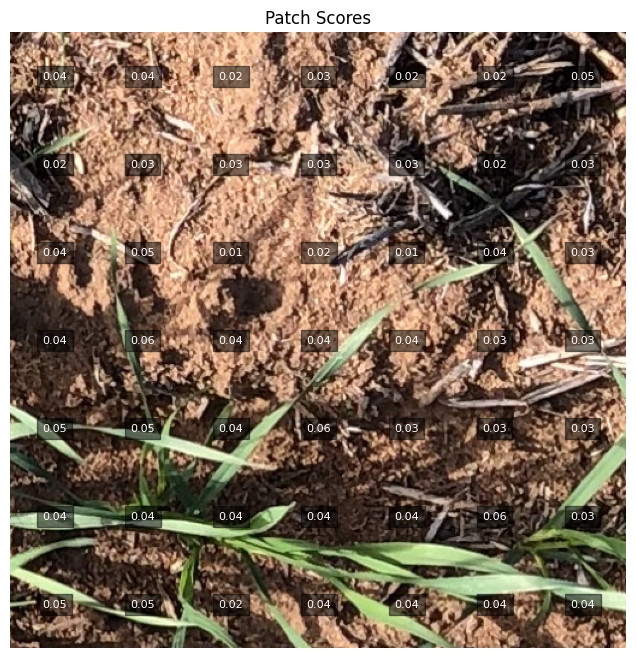

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(sample_image)

H, W = sample_image.shape[:2]

index = 0

for r in range(7):

    for c in range(7):

        y = (r + 0.5) * H / 7
        x = (c + 0.5) * W / 7

        ax.text(

            x,
            y,

            f"{attention[r,c]:.2f}",

            color="white",

            ha="center",

            va="center",

            fontsize=8,

            bbox=dict(
                facecolor="black",
                alpha=0.5
            )

        )

        index += 1

ax.set_title(
    "Patch Scores"
)

ax.axis("off")

plt.show()

In [ ]:
mask_binary = (gt_mask == 255).astype(np.uint8)

H, W = mask_binary.shape

patch_h = H // 7
patch_w = W // 7

patch_cover = []
patch_labels = []

for r in range(7):
    for c in range(7):

        y0 = r * patch_h
        y1 = H if r == 6 else (r + 1) * patch_h

        x0 = c * patch_w
        x1 = W if c == 6 else (c + 1) * patch_w

        patch = mask_binary[y0:y1, x0:x1]

        ratio = patch.mean()

        patch_cover.append(ratio)

        if ratio > 0.20:
            patch_labels.append("Vegetation")
        else:
            patch_labels.append("Background")

patch_cover = np.array(patch_cover).reshape(7,7)

print(patch_cover)

--- GEOMETRY SANITY CHECK ---
Enforced 2D Shape for OpenCV: (512, 512)
Max value in clean mask: 255
[np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0078125), np.float64(0.158203125), np.float64(0.0048828125), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.1123046875), np.float64(0.0185546875), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.005859375), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.1015625), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0927734375), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]


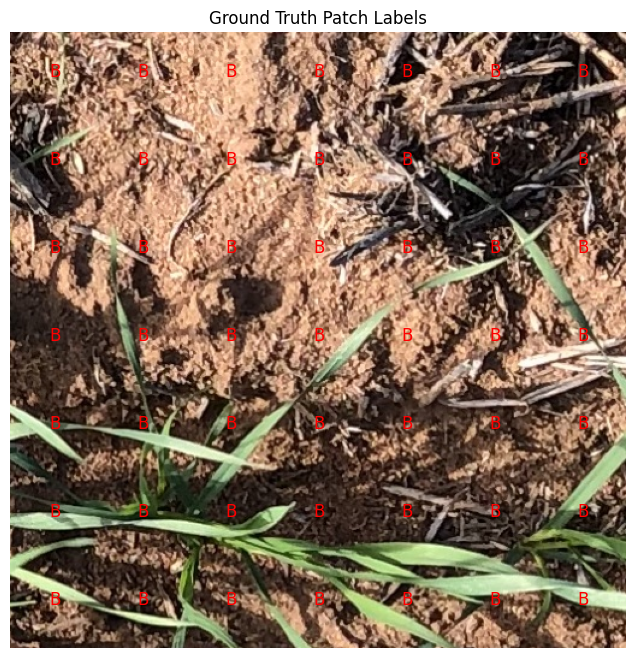

In [ ]:
#display patch labels 
fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(sample_image)

index = 0

H,W = sample_image.shape[:2]

for r in range(7):

    for c in range(7):

        y = (r+0.5)*H/7
        x = (c+0.5)*W/7

        color = "lime"

        if patch_labels[index] == "Background":

            color = "red"

        ax.text(

            x,
            y,

            "V" if patch_labels[index]=="Vegetation" else "B",

            color=color,

            fontsize=12,

            ha="center"

        )

        index += 1

ax.set_title(
    "Ground Truth Patch Labels"
)

ax.axis("off")

plt.show()

In [ ]:
#Compare vegetation and background patch scores
vegetation_scores = []
background_scores = []

for i in range(49):

    if patch_labels[i] == "Vegetation":

        vegetation_scores.append(
            best_positive[i]
        )

    else:

        background_scores.append(
            best_positive[i]
        )

vegetation_scores = np.array(
    vegetation_scores
)

background_scores = np.array(
    background_scores
)

print("Vegetation patches :", len(vegetation_scores))
print("Background patches :", len(background_scores))

Vegetation patches : 0
Background patches : 49


In [ ]:
print(np.unique(gt_mask))

[  0 255]


In [ ]:
#Mean similarity comparision 
print("Vegetation mean similarity :",
      vegetation_scores.mean())

print("Background mean similarity :",
      background_scores.mean())

print()

print("Vegetation std :",
      vegetation_scores.std())

print("Background std :",
      background_scores.std())

Vegetation mean similarity : nan
Background mean similarity : 0.64815044

Vegetation std : nan
Background std : 0.07507209


/tmp/ipykernel_956680/289198314.py:3: RuntimeWarning: Mean of empty slice.
  vegetation_scores.mean())
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/numpy/_core/_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/numpy/_core/_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


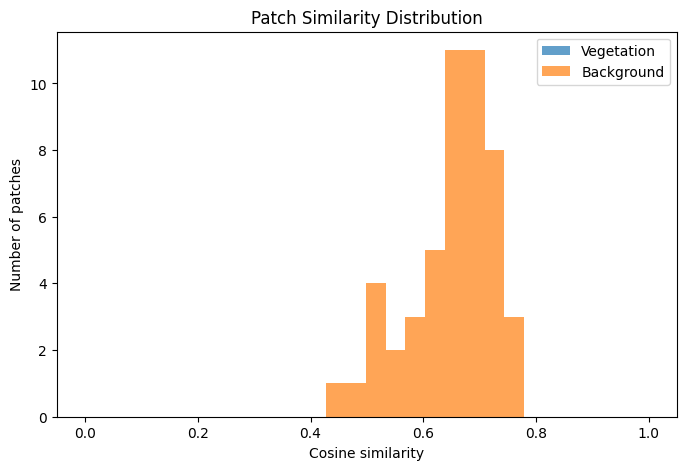

In [ ]:
#Histogram 
plt.figure(figsize=(8,5))

plt.hist(

    vegetation_scores,

    bins=10,

    alpha=0.7,

    label="Vegetation"

)

plt.hist(

    background_scores,

    bins=10,

    alpha=0.7,

    label="Background"

)

plt.xlabel("Cosine similarity")

plt.ylabel("Number of patches")

plt.legend()

plt.title("Patch Similarity Distribution")

plt.show()

/tmp/ipykernel_956680/3640675278.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


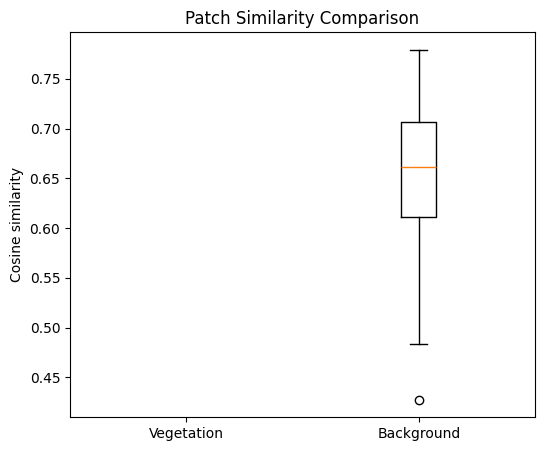

In [ ]:
#Boxplot 
plt.figure(figsize=(6,5))

plt.boxplot(

    [

        vegetation_scores,

        background_scores

    ],

    labels=[

        "Vegetation",

        "Background"

    ]

)

plt.ylabel("Cosine similarity")

plt.title("Patch Similarity Comparison")

plt.show()

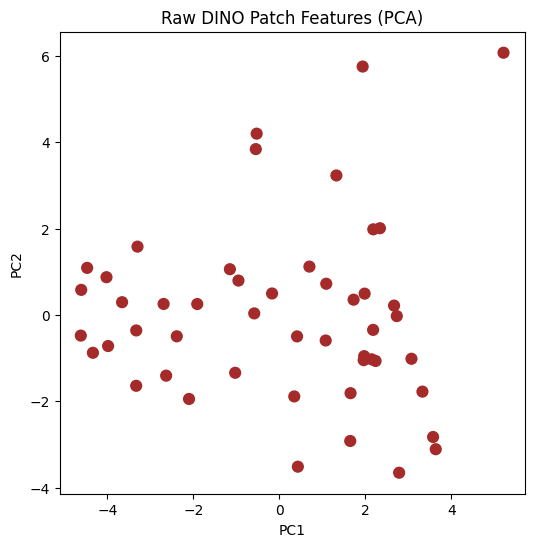

In [ ]:
#PCA vosualization 
pca = PCA(
    n_components=2,
    random_state=42
)

raw_pca = pca.fit_transform(
    patches.numpy()
)

colors = [

    "green"

    if label=="Vegetation"

    else

    "brown"

    for label in patch_labels

]

plt.figure(figsize=(6,6))

plt.scatter(

    raw_pca[:,0],

    raw_pca[:,1],

    c=colors,

    s=60

)

plt.title("Raw DINO Patch Features (PCA)")

plt.xlabel("PC1")

plt.ylabel("PC2")

plt.show()

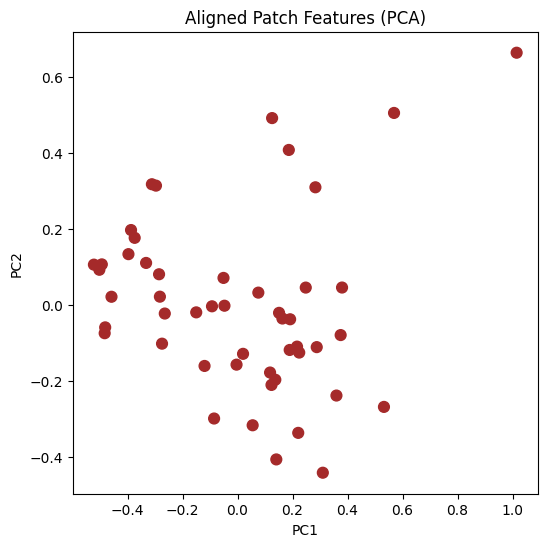

In [ ]:
#PCA after vegann alignment 
pca = PCA(
    n_components=2,
    random_state=42
)

aligned_pca = pca.fit_transform(
    aligned.numpy()
)

plt.figure(figsize=(6,6))

plt.scatter(

    aligned_pca[:,0],

    aligned_pca[:,1],

    c=colors,

    s=60

)

plt.title("Aligned Patch Features (PCA)")

plt.xlabel("PC1")

plt.ylabel("PC2")

plt.show()

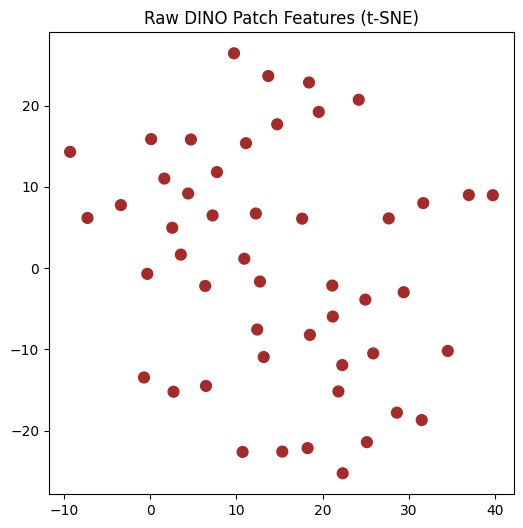

In [ ]:
#t-sne of raw dino features 
tsne = TSNE(

    n_components=2,

    random_state=42,

    perplexity=10

)

raw_tsne = tsne.fit_transform(
    patches.numpy()
)

plt.figure(figsize=(6,6))

plt.scatter(

    raw_tsne[:,0],

    raw_tsne[:,1],

    c=colors,

    s=60

)

plt.title("Raw DINO Patch Features (t-SNE)")

plt.show()

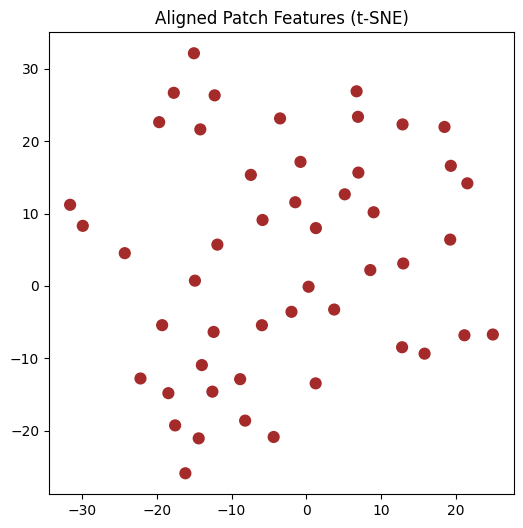

In [ ]:
#t-sne after alignment 
tsne = TSNE(

    n_components=2,

    random_state=42,

    perplexity=10

)

aligned_tsne = tsne.fit_transform(
    aligned.numpy()
)

plt.figure(figsize=(6,6))

plt.scatter(

    aligned_tsne[:,0],

    aligned_tsne[:,1],

    c=colors,

    s=60

)

plt.title("Aligned Patch Features (t-SNE)")

plt.show()